# GMM-EM vs K-means vs DBSCAN Clustering Comparison
## EV Adoption Prediction Dataset

**Course:** Mathematics for Computer Science

### Table of Contents
1. [Setup & Data Loading](#1-setup--data-loading)
2. [Data Preprocessing](#2-data-preprocessing)
3. [K-means Clustering](#3-k-means-clustering)
4. [GMM-EM Clustering](#4-gmm-em-clustering)
5. [DBSCAN Clustering](#5-dbscan-clustering)
6. [Comparison & Metrics](#6-comparison--metrics)
7. [Conclusion](#7-conclusion)

---

## 1. Setup & Data Loading

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
print("Libraries loaded successfully!")

Libraries loaded successfully!


In [ ]:
# Load dataset
# For Colab: upload train.csv to Colab first, then:
# train_df = pd.read_csv('train.csv')

# For Kaggle: use Kaggle dataset path
try:
    train_df = pd.read_csv('dataset/train.csv')
    print(f"Dataset loaded: {train_df.shape[0]} rows, {train_df.shape[1]} columns")
except FileNotFoundError:
    from google.colab import files
    uploaded = files.upload()
    train_df = pd.read_csv(list(uploaded.keys())[0])
    print(f"Dataset loaded: {train_df.shape[0]} rows, {train_df.shape[1]} columns")

Dataset loaded: 668665 rows, 15 columns


---

## 2. Data Preprocessing

In [ ]:
# Subsample for faster execution (use 15,000 samples)
SAMPLE_SIZE = 15000
train_df = train_df.sample(n=SAMPLE_SIZE, random_state=42)
print(f"Using {len(train_df)} samples for analysis")

# Encode categorical variables
categorical_cols = ['Gender', 'City_Type', 'Current_Car_Type', 'Home_Charging_Possible',
                     'Subsidy_Available', 'Range_Anxiety_Level']

df = train_df.copy()
for col in categorical_cols:
    df[col] = LabelEncoder().fit_transform(df[col])

# Encode target
df['Will_Buy_EV'] = LabelEncoder().fit_transform(df['Will_Buy_EV'])

# Features for clustering
feature_cols = [col for col in df.columns if col not in ['id', 'Will_Buy_EV']]
X = df[feature_cols].values
y_true = df['Will_Buy_EV'].values

print(f"Features ({len(feature_cols)}): {feature_cols}")
print(f"Target distribution: {np.bincount(y_true)}")

Using 15000 samples for analysis
Features (13): ['Age', 'Annual_Income_USD', 'Daily_Commute_km', 'Number_of_Cars_Owned', 'Charging_Stations_Near_Home', 'Charging_Stations_Near_Work', 'Environmental_Concern_Level', 'Gender', 'City_Type', 'Current_Car_Type', 'Home_Charging_Possible', 'Subsidy_Available', 'Range_Anxiety_Level']
Target distribution: [12412  2588]


In [ ]:
# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# PCA for 2D visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print(f"PCA explained variance: {sum(pca.explained_variance_ratio_):.1%}")

PCA explained variance: 30.6%


---

## 3. K-means Clustering

### Mathematical Background

K-means minimizes within-cluster sum of squares (WCSS):

$$J = \sum_{i=1}^{n} \sum_{k=1}^{K} ||x_i - \mu_k||^2$$

where $\mu_k$ are cluster centroids. Uses **hard assignment**.

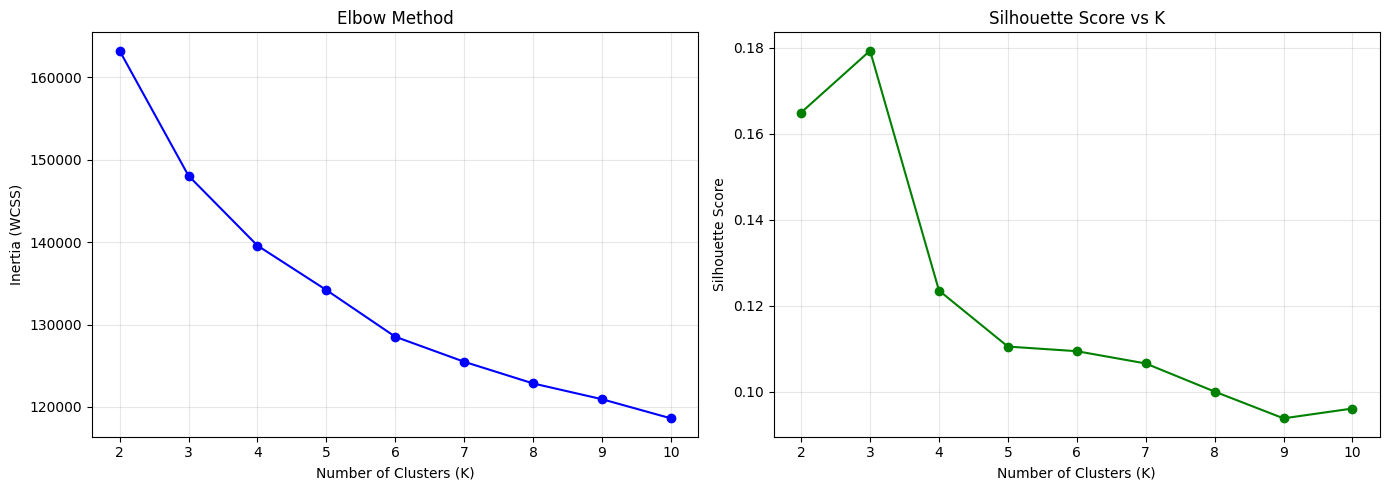

Best K by Silhouette: 3


In [ ]:
# Find optimal K using Elbow and Silhouette
k_range = range(2, 11)
inertias = []
silhouettes = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, km.labels_))

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(k_range, inertias, 'bo-')
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Inertia (WCSS)')
axes[0].set_title('Elbow Method')
axes[0].grid(alpha=0.3)

axes[1].plot(k_range, silhouettes, 'go-')
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Silhouette Score vs K')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('kmeans_elbow_silhouette.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Best K by Silhouette: {k_range[np.argmax(silhouettes)]}")

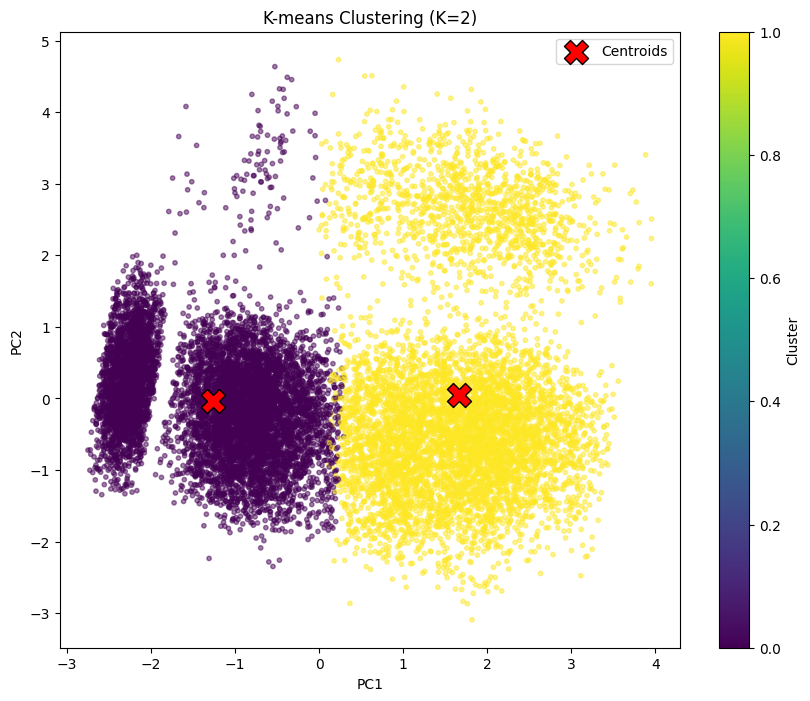

Inertia: 163232.01


In [ ]:
# Fit final K-means
KMEANS_K = 2
kmeans = KMeans(n_clusters=KMEANS_K, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

# Visualize
plt.figure(figsize=(10, 8))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='viridis', alpha=0.5, s=10)
centers_pca = pca.transform(kmeans.cluster_centers_)
plt.scatter(centers_pca[:, 0], centers_pca[:, 1], c='red', marker='X', s=300,
            edgecolors='black', label='Centroids')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title(f'K-means Clustering (K={KMEANS_K})')
plt.colorbar(label='Cluster')
plt.legend()
plt.savefig('kmeans_clusters.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Inertia: {kmeans.inertia_:.2f}")

---

## 4. GMM-EM Clustering

### Mathematical Background

**Gaussian Mixture Model (GMM)** with **Expectation-Maximization (EM)** algorithm.

GMM represents data as a mixture of K Gaussians:

$$P(x) = \sum_{k=1}^{K} \pi_k \mathcal{N}(x | \mu_k, \Sigma_k)$$

**E-step** (soft assignment):
$$r_{ik} = \frac{\pi_k \mathcal{N}(x_i | \mu_k, \Sigma_k)}{\sum_j \pi_j \mathcal{N}(x_i | \mu_j, \Sigma_j)}$$

**M-step** (update parameters):
$$\mu_k = \frac{\sum_i r_{ik} x_i}{\sum_i r_{ik}}$$

Unlike K-means, GMM gives **probability of membership** (soft assignment).

In [ ]:
# Fit GMM-EM
GMM_K = 2
gmm = GaussianMixture(n_components=GMM_K, covariance_type='full',
                     random_state=42, n_init=5, max_iter=200)
gmm.fit(X_scaled)

# Get predictions and probabilities
gmm_labels = gmm.predict(X_scaled)
gmm_probs = gmm.predict_proba(X_scaled)

print(f"Converged: {gmm.converged_}")
print(f"Iterations: {gmm.n_iter_}")
print(f"Log-likelihood: {gmm.score(X_scaled) * len(X_scaled):.2f}")

Converged: True
Iterations: 6
Log-likelihood: -112260.46


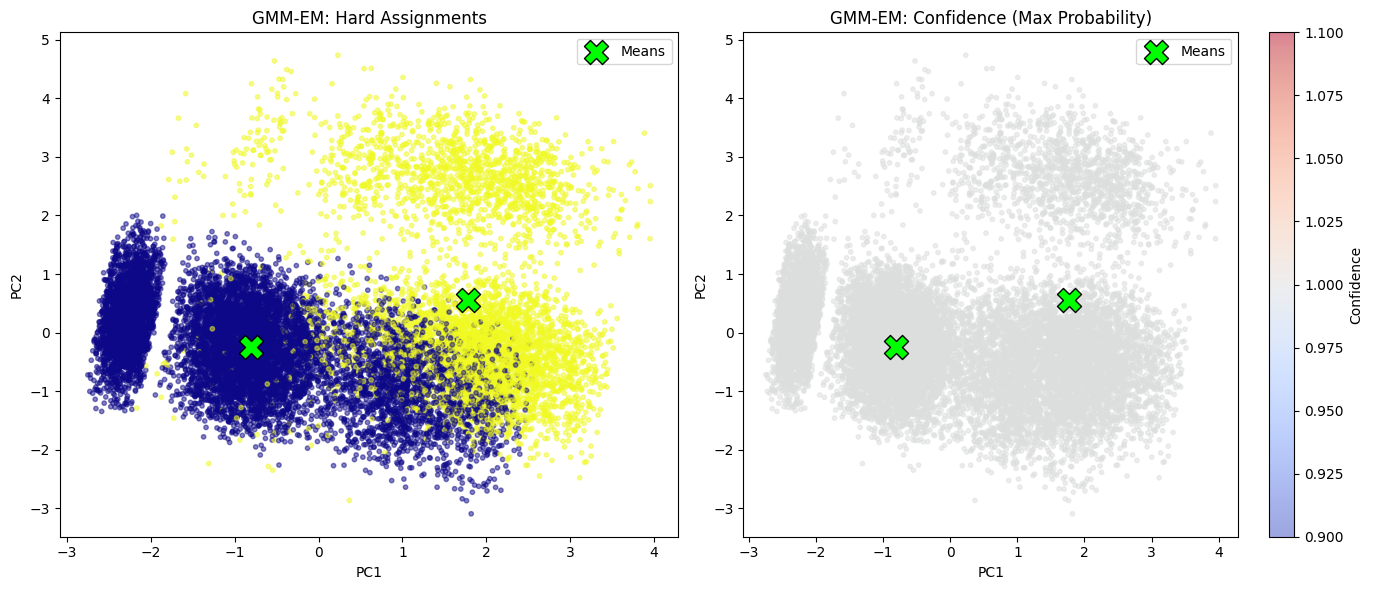

In [ ]:
# Visualize GMM: Hard assignments vs Confidence
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Left: Hard assignments
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=gmm_labels, cmap='plasma', alpha=0.5, s=10)
means_pca = pca.transform(gmm.means_)
axes[0].scatter(means_pca[:, 0], means_pca[:, 1], c='lime', marker='X', s=300,
               edgecolors='black', label='Means')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
axes[0].set_title('GMM-EM: Hard Assignments')
axes[0].legend()

# Right: Confidence (max probability)
max_probs = np.max(gmm_probs, axis=1)
scatter = axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=max_probs, cmap='coolwarm', alpha=0.5, s=10)
axes[1].scatter(means_pca[:, 0], means_pca[:, 1], c='lime', marker='X', s=300,
               edgecolors='black', label='Means')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].set_title('GMM-EM: Confidence (Max Probability)')
axes[1].legend()
plt.colorbar(scatter, ax=axes[1], label='Confidence')

plt.tight_layout()
plt.savefig('gmm_clusters.png', dpi=150, bbox_inches='tight')
plt.show()

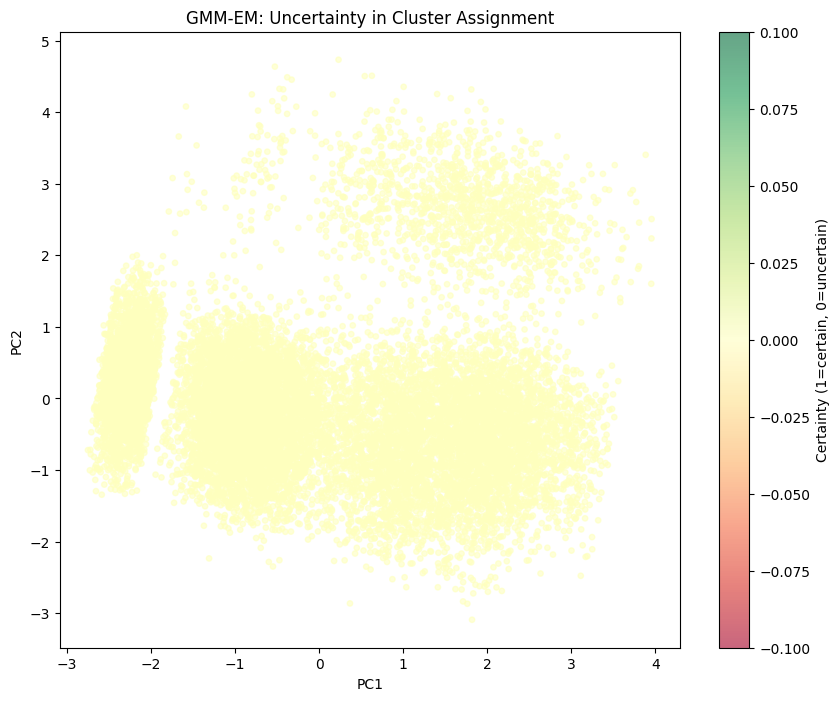

Points with certainty > 80%: 0.0%
Points with certainty < 20%: 100.0%


In [ ]:
# Visualize uncertainty: Points where GMM is uncertain
uncertainty = 1 - 2 * np.abs(gmm_probs[:, 0] - 0.5)

plt.figure(figsize=(10, 8))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=uncertainty, cmap='RdYlGn', alpha=0.6, s=15)
plt.colorbar(scatter, label='Certainty (1=certain, 0=uncertain)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('GMM-EM: Uncertainty in Cluster Assignment')
plt.savefig('gmm_uncertainty.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Points with certainty > 80%: {np.mean(uncertainty > 0.6):.1%}")
print(f"Points with certainty < 20%: {np.mean(uncertainty < 0.2):.1%}")

---

## 5. DBSCAN Clustering

### Mathematical Background

**Density-Based Spatial Clustering of Applications with Noise (DBSCAN)**

- **Core points**: At least `min_samples` neighbors within `eps` radius
- **Border points**: Within `eps` of core points
- **Noise points**: Neither core nor border

Does **not** require specifying K and can detect outliers.

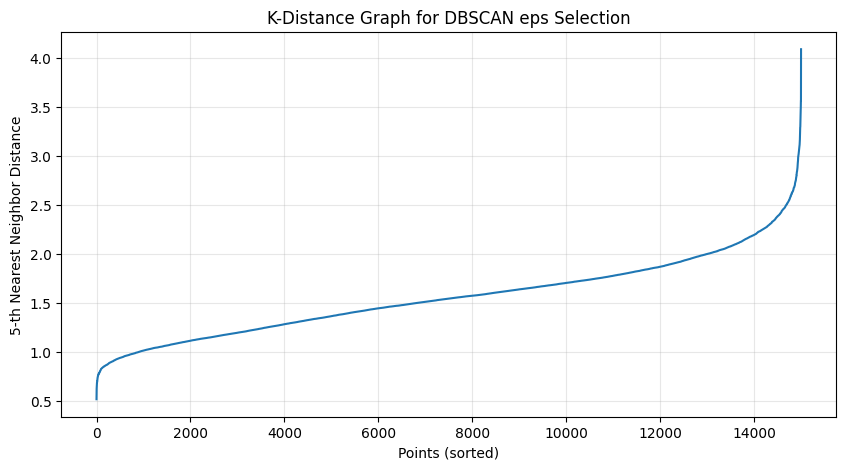

In [ ]:
# Find optimal eps using k-distance graph
k = 5
nn = NearestNeighbors(n_neighbors=k)
nn.fit(X_scaled)
distances, _ = nn.kneighbors(X_scaled)
distances = np.sort(distances[:, k-1])

plt.figure(figsize=(10, 5))
plt.plot(distances)
plt.xlabel('Points (sorted)')
plt.ylabel(f'{k}-th Nearest Neighbor Distance')
plt.title('K-Distance Graph for DBSCAN eps Selection')
plt.grid(alpha=0.3)
plt.savefig('dbscan_kdistance.png', dpi=150, bbox_inches='tight')
plt.show()

# Select eps from the elbow (typically around 1.5-2.5)
DBSCAN_EPS = 2.0
DBSCAN_MIN = 10

In [ ]:
# Fit DBSCAN
dbscan = DBSCAN(eps=DBSCAN_EPS, min_samples=DBSCAN_MIN)
dbscan_labels = dbscan.fit_predict(X_scaled)

n_clusters_dbscan = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = list(dbscan_labels).count(-1)

print(f"Clusters found: {n_clusters_dbscan}")
print(f"Noise points: {n_noise} ({n_noise/len(dbscan_labels):.1%})")

Clusters found: 8
Noise points: 1385 (9.2%)


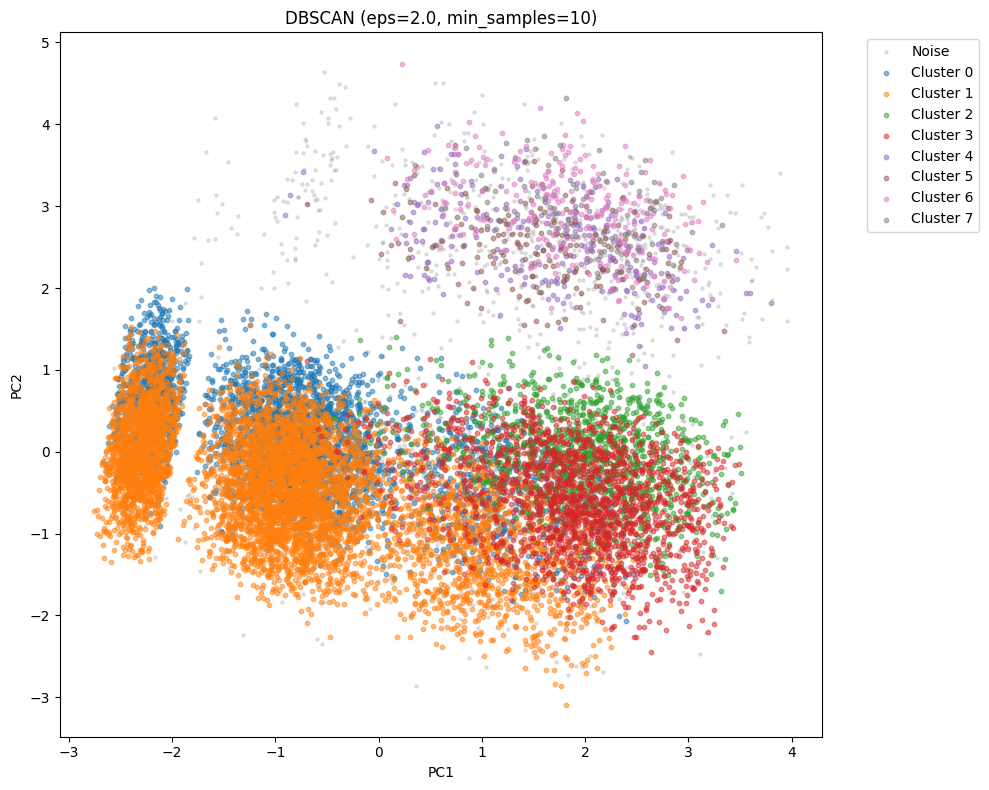

In [ ]:
# Visualize DBSCAN
plt.figure(figsize=(10, 8))
colors = plt.cm.tab10(np.linspace(0, 1, 10))

for i in range(-1, n_clusters_dbscan):
    mask = dbscan_labels == i
    if i == -1:
        plt.scatter(X_pca[mask, 0], X_pca[mask, 1], c='gray', alpha=0.2, s=5, label='Noise')
    else:
        plt.scatter(X_pca[mask, 0], X_pca[mask, 1], c=[colors[i]], alpha=0.5, s=10, label=f'Cluster {i}')

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title(f'DBSCAN (eps={DBSCAN_EPS}, min_samples={DBSCAN_MIN})')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('dbscan_clusters.png', dpi=150, bbox_inches='tight')
plt.show()

---

## 6. Comparison & Metrics

In [ ]:
# Calculate metrics
def calc_metrics(labels, X, y):
    """Calculate clustering metrics"""
    mask = labels >= 0
    if mask.sum() < 2:
        return 0, 0, 0
    return (
        silhouette_score(X[mask], labels[mask]),
        davies_bouldin_score(X[mask], labels[mask]),
        adjusted_rand_score(y[mask], labels[mask])
    )

# K-means metrics
km_sil, km_db, km_ari = calc_metrics(kmeans_labels, X_scaled, y_true)

# GMM metrics
gmm_sil, gmm_db, gmm_ari = calc_metrics(gmm_labels, X_scaled, y_true)

# DBSCAN metrics
db_sil, db_db, db_ari = calc_metrics(dbscan_labels, X_scaled, y_true)

# Display
print("\n" + "=" * 60)
print("METRICS COMPARISON")
print("=" * 60)
print(f"\n{'':15} {'Silhouette':>12} {'Davies-Bouldin':>15} {'ARI':>12}")
print("-" * 60)
print(f"{'K-means':15} {km_sil:>12.4f} {km_db:>15.4f} {km_ari:>12.4f}")
print(f"{'GMM-EM':15} {gmm_sil:>12.4f} {gmm_db:>15.4f} {gmm_ari:>12.4f}")
print(f"{'DBSCAN':15} {db_sil:>12.4f} {db_db:>15.4f} {db_ari:>12.4f}")
print("-" * 60)
print("\nNote: Silhouette (↑=better), Davies-Bouldin (↓=better), ARI (↑=better)")


METRICS COMPARISON

                  Silhouette  Davies-Bouldin          ARI
------------------------------------------------------------
K-means               0.1649          2.2271      -0.0057
GMM-EM                0.1653          2.3286      -0.0285
DBSCAN                0.0961          2.5860      -0.0283
------------------------------------------------------------

Note: Silhouette (↑=better), Davies-Bouldin (↓=better), ARI (↑=better)


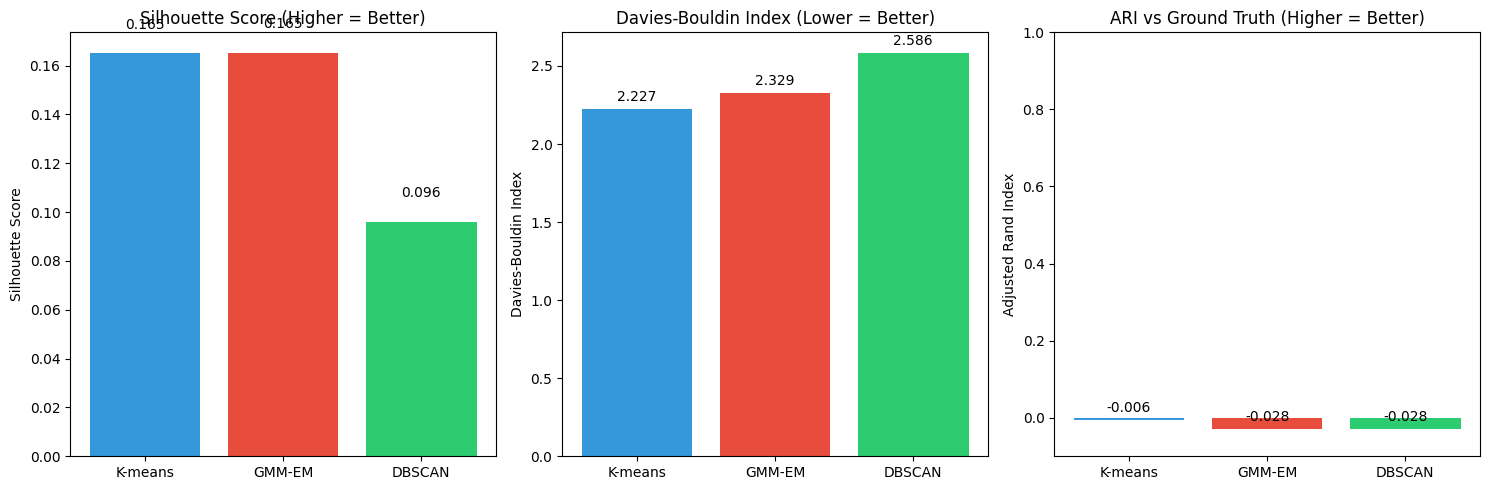

In [ ]:
# Visualize metrics comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
methods = ['K-means', 'GMM-EM', 'DBSCAN']
colors = ['#3498db', '#e74c3c', '#2ecc71']

# Silhouette
bars1 = axes[0].bar(methods, [km_sil, gmm_sil, db_sil], color=colors)
axes[0].set_ylabel('Silhouette Score')
axes[0].set_title('Silhouette Score (Higher = Better)')
for bar, v in zip(bars1, [km_sil, gmm_sil, db_sil]):
    axes[0].text(bar.get_x() + bar.get_width()/2, v + 0.01, f'{v:.3f}', ha='center')

# Davies-Bouldin
bars2 = axes[1].bar(methods, [km_db, gmm_db, db_db], color=colors)
axes[1].set_ylabel('Davies-Bouldin Index')
axes[1].set_title('Davies-Bouldin Index (Lower = Better)')
for bar, v in zip(bars2, [km_db, gmm_db, db_db]):
    axes[1].text(bar.get_x() + bar.get_width()/2, v + 0.05, f'{v:.3f}', ha='center')

# ARI
bars3 = axes[2].bar(methods, [km_ari, gmm_ari, db_ari], color=colors)
axes[2].set_ylabel('Adjusted Rand Index')
axes[2].set_title('ARI vs Ground Truth (Higher = Better)')
axes[2].set_ylim([-0.1, 1])
for bar, v in zip(bars3, [km_ari, gmm_ari, db_ari]):
    axes[2].text(bar.get_x() + bar.get_width()/2, v + 0.02, f'{v:.3f}', ha='center')

plt.tight_layout()
plt.savefig('metrics_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

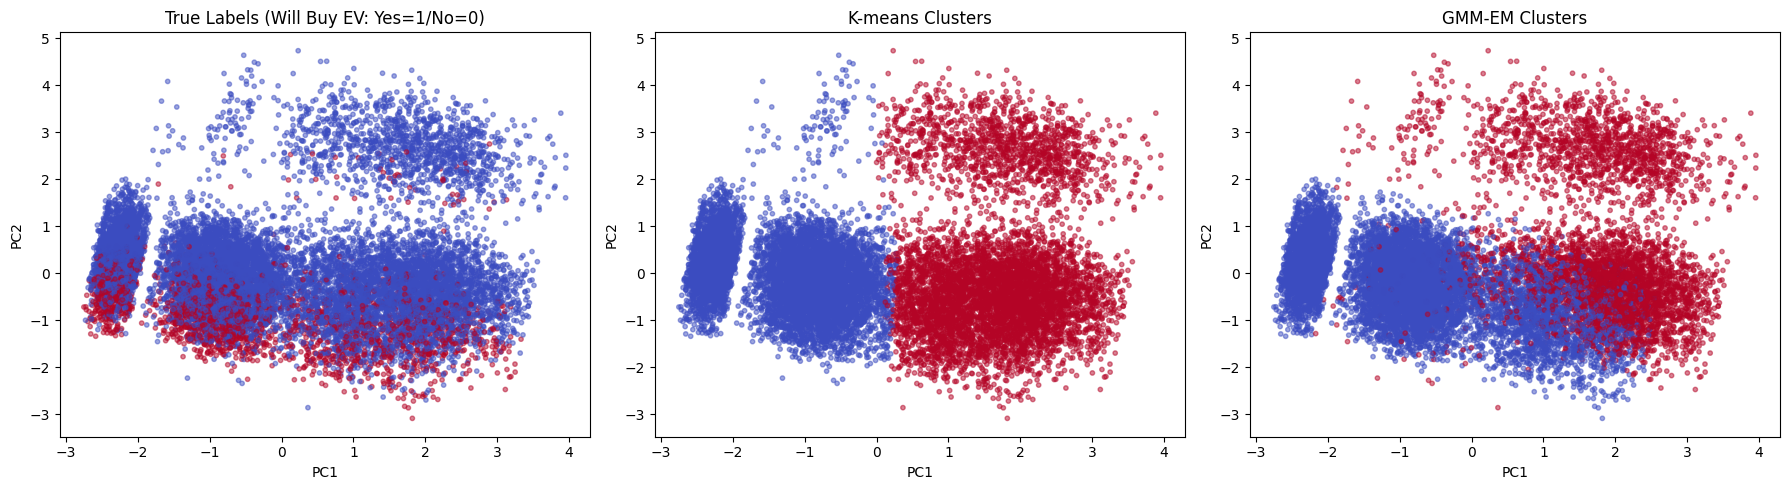

In [ ]:
# Compare with true labels
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=y_true, cmap='coolwarm', alpha=0.5, s=10)
axes[0].set_title('True Labels (Will Buy EV: Yes=1/No=0)')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')

axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='coolwarm', alpha=0.5, s=10)
axes[1].set_title('K-means Clusters')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')

axes[2].scatter(X_pca[:, 0], X_pca[:, 1], c=gmm_labels, cmap='coolwarm', alpha=0.5, s=10)
axes[2].set_title('GMM-EM Clusters')
axes[2].set_xlabel('PC1')
axes[2].set_ylabel('PC2')

plt.tight_layout()
plt.savefig('true_vs_predicted.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# Save metrics to CSV
metrics_df = pd.DataFrame({
    'Method': ['K-means', 'GMM-EM', 'DBSCAN'],
    'Silhouette': [km_sil, gmm_sil, db_sil],
    'Davies-Bouldin': [km_db, gmm_db, db_db],
    'ARI': [km_ari, gmm_ari, db_ari]
})
metrics_df.to_csv('clustering_metrics.csv', index=False)
print("Metrics saved to 'clustering_metrics.csv'")
print(metrics_df.to_string(index=False))

Metrics saved to 'clustering_metrics.csv'
 Method  Silhouette  Davies-Bouldin       ARI
K-means    0.164939        2.227057 -0.005741
 GMM-EM    0.165325        2.328649 -0.028492
 DBSCAN    0.096061        2.586034 -0.028267


---

## 7. Conclusion

In [ ]:
print("\n" + "=" * 60)
print("SUMMARY: GMM-EM vs K-means vs DBSCAN")
print("=" * 60)
summary = """
| Method   | Assignment | Pros                          | Cons                          |
|----------|-----------|-------------------------------|-------------------------------|
| K-means  | Hard      | Fast, Simple                  | Sensitive to init, spherical  |
| GMM-EM   | Soft      | Probabilities, flexible       | Slower, local optima          |
| DBSCAN   | Density   | No K needed, detects outliers | Sensitive to hyperparameters  |
"""
print(summary)

print("\nKey Findings:")
print("-" * 60)
if gmm_sil > km_sil:
    print(f"• GMM-EM has slightly better Silhouette ({gmm_sil:.4f} vs {km_sil:.4f})")
else:
    print(f"• K-means has better Silhouette ({km_sil:.4f} vs {gmm_sil:.4f})")

print(f"• GMM-EM advantage: Can express uncertainty via soft assignments")
print(f"• DBSCAN found {n_clusters_dbscan} natural clusters + {n_noise} outliers")

print("\n" + "=" * 60)
print("Generated Files:")
print("-" * 60)
print("- kmeans_elbow_silhouette.png")
print("- kmeans_clusters.png")
print("- gmm_clusters.png")
print("- gmm_uncertainty.png")
print("- dbscan_kdistance.png")
print("- dbscan_clusters.png")
print("- metrics_comparison.png")
print("- true_vs_predicted.png")
print("- clustering_metrics.csv")
print("=" * 60)


SUMMARY: GMM-EM vs K-means vs DBSCAN

| Method   | Assignment | Pros                          | Cons                          |
|----------|-----------|-------------------------------|-------------------------------|
| K-means  | Hard      | Fast, Simple                  | Sensitive to init, spherical  |
| GMM-EM   | Soft      | Probabilities, flexible       | Slower, local optima          |
| DBSCAN   | Density   | No K needed, detects outliers | Sensitive to hyperparameters  |


Key Findings:
------------------------------------------------------------
• GMM-EM has slightly better Silhouette (0.1653 vs 0.1649)
• GMM-EM advantage: Can express uncertainty via soft assignments
• DBSCAN found 8 natural clusters + 1385 outliers

Generated Files:
------------------------------------------------------------
- kmeans_elbow_silhouette.png
- kmeans_clusters.png
- gmm_clusters.png
- gmm_uncertainty.png
- dbscan_kdistance.png
- dbscan_clusters.png
- metrics_comparison.png
- true_vs_predicted.pn